In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
pvz=pd.read_csv('PvZ2 Plants Analysis Assignment Dataset.csv')
pvz.head()

,Plant Name,Family,Acquisition Cost,Acquisition Method,Acquisition Location,Sun Cost,Range,Area,Usage,Special,Recharge Speed,Toughness,Damage,Sun Production
0,Enlighten-mint,Enlighten-mint,100,Purchased with Mints,Not From Worlds,0.0,Full Board,Full Board,"Single, Instant","Gives a Burst of Sun, Temporarily Boosts all E...",85.0,100000.0,NaN,Normal
1,Sunflower,Enlighten-mint,0,Unlocked During Tutorial,Player's house,50.0,NaN,NaN,NaN,NaN,5.0,300.0,NaN,Normal
2,Twin Sunflower,Enlighten-mint,0,Unlocked During Levels,Ancient Egypt,125.0,NaN,NaN,NaN,NaN,10.0,300.0,NaN,Double
3,Sun-shroom,Enlighten-mint,0,Unlocked During Levels,Dark Ages,25.0,NaN,NaN,Grows into Larger Sun Producer Over Time,Variable Sun Production,5.0,300.0,NaN,Variable
4,Sun Bean,Enlighten-mint,0,Unlocked During Levels,Dark Ages,50.0,NaN,NaN,"Single, On Contact",Zombies Drop Sun When Defeated,20.0,NaN,NaN,Variable


In [3]:
print('Number of rows:',pvz.shape[0])
print('Number of columns:',pvz.shape[1],'\n')

print('Dataset information:')
pvz.info()

Number of rows: 215
Number of columns: 14 

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Plant Name            215 non-null    str    
 1   Family                215 non-null    str    
 2   Acquisition Cost      215 non-null    int64  
 3   Acquisition Method    215 non-null    str    
 4   Acquisition Location  215 non-null    str    
 5   Sun Cost              213 non-null    float64
 6   Range                 137 non-null    str    
 7   Area                  72 non-null     str    
 8   Usage                 123 non-null    str    
 9   Special               170 non-null    str    
 10  Recharge Speed        213 non-null    float64
 11  Toughness             181 non-null    float64
 12  Damage                160 non-null    float64
 13  Sun Production        11 non-null     str    
dtypes: float64(4), int64

In [4]:
pvz.describe(include='all')

,Plant Name,Family,Acquisition Cost,Acquisition Method,Acquisition Location,Sun Cost,Range,Area,Usage,Special,Recharge Speed,Toughness,Damage,Sun Production
count,215,215,215.000000,215,215,213.000000,137,72,123,170,213.000000,181.000000,160.000000,11
unique,214,18,NaN,10,16,NaN,19,15,73,164,NaN,NaN,NaN,5
top,Strawburst,Enforce-mint,NaN,Collection of Seed Packets,Not From Worlds,NaN,Straight,3x3,"Single, Instant",Slows Zombies,NaN,NaN,NaN,Variable
freq,2,19,NaN,93,144,NaN,24,29,35,3,NaN,NaN,NaN,5
mean,NaN,NaN,135.246512,NaN,NaN,134.694836,NaN,NaN,NaN,NaN,18.408451,5130.939227,359.293750,NaN
std,NaN,NaN,106.856615,NaN,NaN,96.125536,NaN,NaN,NaN,NaN,21.072647,20496.448776,687.220814,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,5.000000,50.000000,4.000000,NaN
25%,NaN,NaN,0.000000,NaN,NaN,75.000000,NaN,NaN,NaN,NaN,5.000000,300.000000,25.000000,NaN
50%,NaN,NaN,150.000000,NaN,NaN,125.000000,NaN,NaN,NaN,NaN,12.000000,300.000000,50.000000,NaN
75%,NaN,NaN,250.000000,NaN,NaN,175.000000,NaN,NaN,NaN,NaN,20.000000,400.000000,200.000000,NaN


In [5]:
cca_pvz=pvz.dropna()
print('Original dataset:',pvz.shape)
print('Edited dataset:',cca_pvz.shape,'\n')

print('%loss:',((len(pvz)-len(cca_pvz))/len(pvz))*100,'\n')

print('OG sun cost mean:',pvz['Sun Cost'].mean())
print('New sun cost mean:',cca_pvz['Sun Cost'].mean(),'\n')
a=pvz['Sun Cost'].mean()
b=cca_pvz['Sun Cost'].mean()
print('Since the difference',b-a, 'is very small we can do a complete case analysis as well')

missing_values=pvz.isnull().sum()
missing_percentage=(pvz.isnull().sum()/len(pvz))*100

missing_summary=pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage':missing_percentage
})

missing_summary

Original dataset: (215, 14)
Edited dataset: (0, 14) 

%loss: 100.0 

OG sun cost mean: 134.69483568075117
New sun cost mean: nan 

Since the difference nan is very small we can do a complete case analysis as well


,Missing Values,Missing Percentage
Plant Name,0,0.000000
Family,0,0.000000
Acquisition Cost,0,0.000000
Acquisition Method,0,0.000000
Acquisition Location,0,0.000000
Sun Cost,2,0.930233
Range,78,36.279070
Area,143,66.511628
Usage,92,42.790698
Special,45,20.930233


In [6]:
numeric_columns=['Sun Cost','Recharge Speed','Toughness']
print(pvz[numeric_columns].isnull().sum(),'\n')

categorical_columns=['Range','Area','Usage','Special']
pvz[categorical_columns].isnull().sum()

Sun Cost           2
Recharge Speed     2
Toughness         34
dtype: int64 



Range       78
Area       143
Usage       92
Special     45
dtype: int64

In [7]:
numeric_columns=['Sun Cost','Recharge Speed','Toughness']
for col in numeric_columns:
    pvz[col]=pvz[col].fillna(pvz[col].median())
pvz['Damage']=pvz['Damage'].fillna(0)

print(pvz[numeric_columns].isnull().sum())

Sun Cost          0
Recharge Speed    0
Toughness         0
dtype: int64


In [8]:
categorical_columns=['Range','Area','Usage','Special']

for col in categorical_columns:
    pvz[col]=pvz[col].fillna('Not Specified')

pvz[categorical_columns].isnull().sum()

Range      0
Area       0
Usage      0
Special    0
dtype: int64

In [9]:
pvz[pvz['Plant Name'].str.contains('Strawburst',case=False,na=False)]

,Plant Name,Family,Acquisition Cost,Acquisition Method,Acquisition Location,Sun Cost,Range,Area,Usage,Special,Recharge Speed,Toughness,Damage,Sun Production
51,Strawburst,Bombard-mint,199,Purchased with Real Money,Not From Worlds,400.0,Not Specified,3x3,Tap to Use,Different Damage and Radius Depending on its G...,5.0,300.0,900.0,NaN
151,Strawburst,Pepper-mint,199,Purchased with Real Money,Not From Worlds,400.0,Not Specified,3x3,Tap to Use,Growth Speed,5.0,300.0,900.0,NaN


In [10]:
wrong_record=pvz[
        (pvz['Plant Name'].str.strip().str.lower()=='strawburst') &
         (pvz['Family'].str.strip().str.lower()=='pepper-mint')
    ].index

pvz.drop(wrong_record,inplace=True)

pvz[pvz['Plant Name'].str.contains('Strawburst',case=False,na=False)]

,Plant Name,Family,Acquisition Cost,Acquisition Method,Acquisition Location,Sun Cost,Range,Area,Usage,Special,Recharge Speed,Toughness,Damage,Sun Production
51,Strawburst,Bombard-mint,199,Purchased with Real Money,Not From Worlds,400.0,Not Specified,3x3,Tap to Use,Different Damage and Radius Depending on its G...,5.0,300.0,900.0,NaN


In [11]:
print(pvz.shape)

(214, 14)


In [12]:
text_columns=['Plant Name','Family','Acquisition Method','Acquisition Location']

for col in text_columns:
    pvz[col]=(pvz[col].astype('string').str.strip())

In [13]:
print(pvz['Acquisition Method'].unique())
print('\n')
print(pvz['Acquisition Method'].value_counts())

<ArrowStringArray>
[      'Purchased with Mints',   'Unlocked During Tutorial',
     'Unlocked During Levels',  'Purchased with Real Money',
 'Collection of seed Packets', 'Collection of Seed Packets',
        'Purchased with Gems',     'UNLOCKED DURING LEVELS',
    'Collection of Seed Pack',       'purchased with mints']
Length: 10, dtype: string


Acquisition Method
Collection of Seed Packets    93
Unlocked During Levels        63
Purchased with Real Money     21
Purchased with Gems           15
Purchased with Mints          13
Unlocked During Tutorial       5
Collection of seed Packets     1
UNLOCKED DURING LEVELS         1
Collection of Seed Pack        1
purchased with mints           1
Name: count, dtype: int64[pyarrow]


In [14]:
pvz['Acquisition Method']=pvz['Acquisition Method'].replace({
    'Collection of seed Packets':'Collection of Seed Packets',
    'Collection of Seed Pack':'Collection of Seed Packets',
    'UNLOCKED DURING LEVELS':'Unlocked During Levels',
    'purchased with mints':'Purchased with Mints',
})
print(pvz['Acquisition Method'].value_counts())

Acquisition Method
Collection of Seed Packets    95
Unlocked During Levels        64
Purchased with Real Money     21
Purchased with Gems           15
Purchased with Mints          14
Unlocked During Tutorial       5
Name: count, dtype: int64[pyarrow]


In [15]:
pvz['Sun Production'].value_counts(dropna=False)

Sun Production
NaN         203
Variable      5
Normal        3
Double        1
Large         1
450           1
Name: count, dtype: int64

In [16]:
pvz=pvz.drop(columns=['Sun Production'])
print(pvz.shape)

(214, 13)


In [17]:
acquisition_mapping={
    'Collection of Seed Packets':'Collected',
    'Purchased with Mints':'Purchased',
    'Purchased with Gems':'Purchased',
    'Purchased with Real Money':'Purchased',
    'Unlocked During Tutorial':'Unlocked',
    'Unlocked During Levels':'Unlocked'
}

In [18]:
pvz['Acquisition Category']=(pvz['Acquisition Method'].map(acquisition_mapping))
print(pvz[['Plant Name','Acquisition Method','Acquisition Category']])

            Plant Name          Acquisition Method Acquisition Category
0       Enlighten-mint        Purchased with Mints            Purchased
1            Sunflower    Unlocked During Tutorial             Unlocked
2       Twin Sunflower      Unlocked During Levels             Unlocked
3           Sun-shroom      Unlocked During Levels             Unlocked
4             Sun Bean      Unlocked During Levels             Unlocked
..                 ...                         ...                  ...
210  Shadow Peashooter  Collection of Seed Packets            Collected
211     Murkademia Nut  Collection of Seed Packets            Collected
212         Gloom Vine  Collection of Seed Packets            Collected
213          Noctarine  Collection of Seed Packets            Collected
214       Dragon Bruit  Collection of Seed Packets            Collected

[214 rows x 3 columns]


In [19]:
pvz['Sun Cost Category']=pd.qcut(pvz['Sun Cost'],q=4,labels=['Low Cost','Medium Cost','High Cost','Very High Cost'])
print(pvz['Sun Cost Category'].value_counts().sort_index())

Sun Cost Category
Low Cost          67
Medium Cost       42
High Cost         62
Very High Cost    43
Name: count, dtype: int64


In [20]:
pvz['Toughness Bin'] = pd.qcut(
    pvz['Toughness'],
    q=5, labels=['Weak','Strong','Very Strong'],
    duplicates='drop'
)

print(pvz['Toughness Bin'].value_counts().sort_index())

Toughness Bin
Weak           164
Strong           8
Very Strong     42
Name: count, dtype: int64


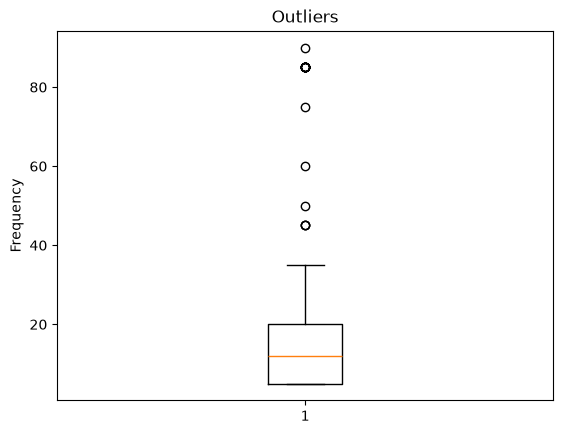



5.0 20.0 

15.0 

Lower: -2.5
Upper: 42.5 

Number of Outliers Present: 21 

OG Dataset Shape: (214, 16)
Trimmed Dataset Shape: (193, 16) 



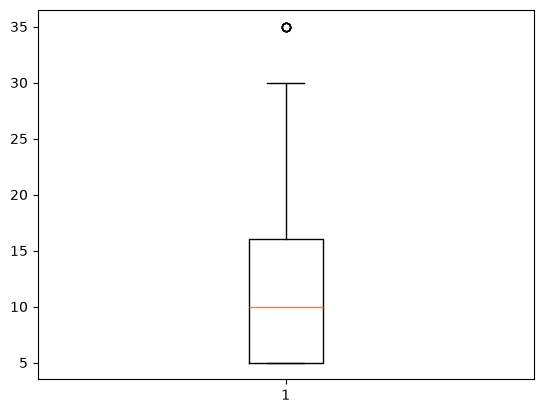

In [21]:
plt.boxplot(pvz['Recharge Speed'])
plt.title('Outliers')
plt.ylabel('Frequency')
plt.show()
print('\n')

Q1=pvz['Recharge Speed'].quantile(0.25)
Q3=pvz['Recharge Speed'].quantile(0.75)
print(Q1,Q3,'\n')

IQR=Q3-Q1
print(IQR,'\n')

lower=Q3-1.5*IQR
upper=Q3+1.5*IQR
print('Lower:',lower)
print('Upper:',upper,'\n')

nos=pvz[
    (pvz['Recharge Speed']<lower) |
    (pvz['Recharge Speed']>upper)
    ]
print('Number of Outliers Present:',len(nos),'\n')

trimmed_pvz=pvz[
    (pvz['Recharge Speed']>=lower) &
    (pvz['Recharge Speed']<=upper)
    ]

print('OG Dataset Shape:', pvz.shape)
print('Trimmed Dataset Shape:',trimmed_pvz.shape,'\n')

plt.boxplot(trimmed_pvz['Recharge Speed'])
plt.show()

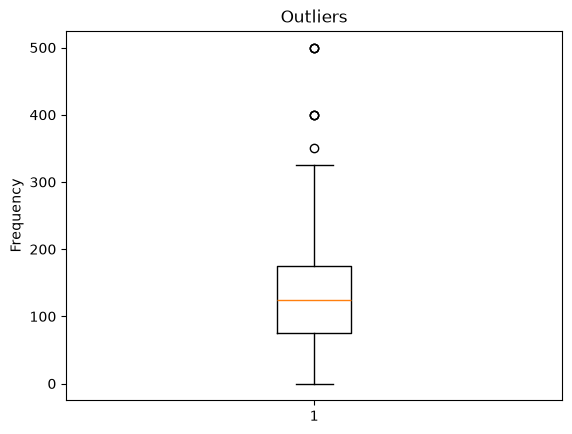



75.0 175.0 

100.0 

Lower: 25.0
Upper: 325.0 

Number of Outliers Present: 31 

OG Dataset Shape: (214, 16)
Trimmed Dataset Shape: (183, 16) 



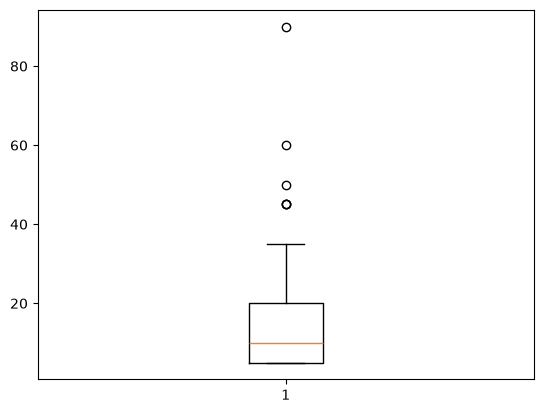

In [22]:
plt.boxplot(pvz['Sun Cost'])
plt.title('Outliers')
plt.ylabel('Frequency')
plt.show()
print('\n')

Q1=pvz['Sun Cost'].quantile(0.25)
Q3=pvz['Sun Cost'].quantile(0.75)
print(Q1,Q3,'\n')

IQR=Q3-Q1
print(IQR,'\n')

lower=Q3-1.5*IQR
upper=Q3+1.5*IQR
print('Lower:',lower)
print('Upper:',upper,'\n')

nos1=pvz[
    (pvz['Sun Cost']<lower) |
    (pvz['Sun Cost']>upper)
    ]
print('Number of Outliers Present:',len(nos1),'\n')

trimmed_pvz1=pvz[
    (pvz['Sun Cost']>=lower) &
    (pvz['Sun Cost']<=upper)
    ]

print('OG Dataset Shape:', pvz.shape)
print('Trimmed Dataset Shape:',trimmed_pvz1.shape,'\n')

plt.boxplot(trimmed_pvz1['Recharge Speed'])
plt.show()

In [23]:
print('EPLORATORY ANALYSIS:','\n')
print('Frequency of Each Category:')
print(pvz['Acquisition Category'].value_counts())

EPLORATORY ANALYSIS: 

Frequency of Each Category:
Acquisition Category
Collected    95
Unlocked     69
Purchased    50
Name: count, dtype: int64


In [24]:
pvz.groupby('Acquisition Category')['Damage'].mean().sort_values()

Acquisition Category
Unlocked     167.971014
Collected    259.357895
Purchased    407.160000
Name: Damage, dtype: float64

In [25]:
pvz.groupby('Sun Cost Category')['Damage'].mean().sort_values()

Sun Cost Category
Medium Cost       192.761905
Very High Cost    257.604651
Low Cost          281.746269
High Cost         298.983871
Name: Damage, dtype: float64

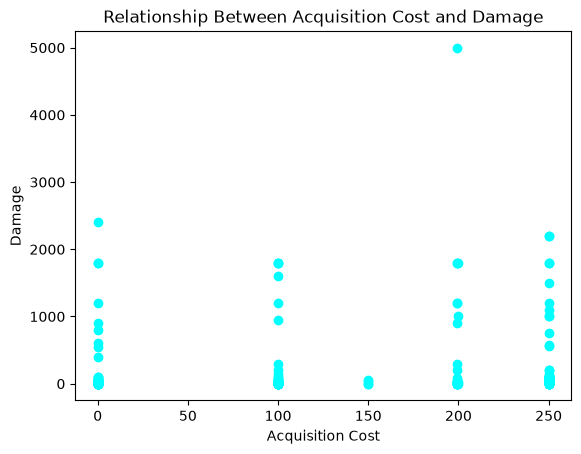

In [26]:
plt.scatter(pvz['Acquisition Cost'],pvz['Damage'],color='cyan')
plt.xlabel('Acquisition Cost')
plt.ylabel('Damage')
plt.title('Relationship Between Acquisition Cost and Damage')
plt.show()

In [27]:
pvz_categorical=pvz.copy()
pvz_categorical['Acquisition Category']=pvz_categorical['Acquisition Category'].map({'Unlocked':1,'Purchased':2,'Collected':3})
print(pvz_categorical[['Plant Name','Acquisition Method','Acquisition Category']])

            Plant Name          Acquisition Method  Acquisition Category
0       Enlighten-mint        Purchased with Mints                     2
1            Sunflower    Unlocked During Tutorial                     1
2       Twin Sunflower      Unlocked During Levels                     1
3           Sun-shroom      Unlocked During Levels                     1
4             Sun Bean      Unlocked During Levels                     1
..                 ...                         ...                   ...
210  Shadow Peashooter  Collection of Seed Packets                     3
211     Murkademia Nut  Collection of Seed Packets                     3
212         Gloom Vine  Collection of Seed Packets                     3
213          Noctarine  Collection of Seed Packets                     3
214       Dragon Bruit  Collection of Seed Packets                     3

[214 rows x 3 columns]


In [28]:
pvz=pd.get_dummies(pvz, columns=['Acquisition Category'],prefix='Acquisition')
print(pvz.head())

       Plant Name          Family  Acquisition Cost        Acquisition Method  \
0  Enlighten-mint  Enlighten-mint               100      Purchased with Mints   
1       Sunflower  Enlighten-mint                 0  Unlocked During Tutorial   
2  Twin Sunflower  Enlighten-mint                 0    Unlocked During Levels   
3      Sun-shroom  Enlighten-mint                 0    Unlocked During Levels   
4        Sun Bean  Enlighten-mint                 0    Unlocked During Levels   

  Acquisition Location  Sun Cost          Range           Area  \
0      Not From Worlds       0.0     Full Board     Full Board   
1       Player's house      50.0  Not Specified  Not Specified   
2        Ancient Egypt     125.0  Not Specified  Not Specified   
3            Dark Ages      25.0  Not Specified  Not Specified   
4            Dark Ages      50.0  Not Specified  Not Specified   

                                      Usage  \
0                           Single, Instant   
1                     

In [29]:
original_pvz=pd.read_csv('PvZ2 Plants Analysis Assignment Dataset.csv')
comparison=pd.DataFrame({
    'Before Cleaning':
    original_pvz.isnull().sum(),

    'After Cleaning':
    pvz.isnull().sum()
})

comparison

,Before Cleaning,After Cleaning
Acquisition Cost,0.0,0.0
Acquisition Location,0.0,0.0
Acquisition Method,0.0,0.0
Acquisition_Collected,NaN,0.0
Acquisition_Purchased,NaN,0.0
Acquisition_Unlocked,NaN,0.0
Area,143.0,0.0
Damage,55.0,0.0
Family,0.0,0.0
Plant Name,0.0,0.0


In [30]:
print('Before Cleaning Shape:',original_pvz.shape)
print('After Cleaning Shape:',pvz.shape)

Before Cleaning Shape: (215, 14)
After Cleaning Shape: (214, 18)


In [31]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

pvz

,Plant Name,Family,Acquisition Cost,Acquisition Method,Acquisition Location,Sun Cost,Range,Area,Usage,Special,Recharge Speed,Toughness,Damage,Sun Cost Category,Toughness Bin,Acquisition_Collected,Acquisition_Purchased,Acquisition_Unlocked
0,Enlighten-mint,Enlighten-mint,100,Purchased with Mints,Not From Worlds,0.0,Full Board,Full Board,"Single, Instant","Gives a Burst of Sun, Temporarily Boosts all E...",85.0,100000.0,0.0,Low Cost,Very Strong,False,True,False
1,Sunflower,Enlighten-mint,0,Unlocked During Tutorial,Player's house,50.0,Not Specified,Not Specified,Not Specified,Not Specified,5.0,300.0,0.0,Low Cost,Weak,False,False,True
2,Twin Sunflower,Enlighten-mint,0,Unlocked During Levels,Ancient Egypt,125.0,Not Specified,Not Specified,Not Specified,Not Specified,10.0,300.0,0.0,Medium Cost,Weak,False,False,True
3,Sun-shroom,Enlighten-mint,0,Unlocked During Levels,Dark Ages,25.0,Not Specified,Not Specified,Grows into Larger Sun Producer Over Time,Variable Sun Production,5.0,300.0,0.0,Low Cost,Weak,False,False,True
4,Sun Bean,Enlighten-mint,0,Unlocked During Levels,Dark Ages,50.0,Not Specified,Not Specified,"Single, On Contact",Zombies Drop Sun When Defeated,20.0,300.0,0.0,Low Cost,Weak,False,False,True
5,Toadstool,Enlighten-mint,199,Purchased with Real Money,Not From Worlds,200.0,Close,Not Specified,Licks up the Nearest Zombie and Chews,Not Specified,5.0,300.0,0.0,Very High Cost,Weak,False,True,False
6,Gold Leaf,Enlighten-mint,0,Unlocked During Levels,Lost City,75.0,Not Specified,Not Specified,"Single, Instant",Creates a Gold Tile on Planting which Enables ...,50.0,300.0,0.0,Low Cost,Weak,False,False,True
7,Primal Sunflower,Enlighten-mint,0,Unlocked During Levels,Jurassic Marsh,75.0,Not Specified,Not Specified,Not Specified,Not Specified,5.0,300.0,0.0,Low Cost,Weak,False,False,True
8,Gold Bloom,Enlighten-mint,199,Purchased with Real Money,Not From Worlds,0.0,Not Specified,Not Specified,"Single, Instant",Not Specified,75.0,300.0,0.0,Low Cost,Weak,False,True,False
9,Solar Tomato,Enlighten-mint,150,Collection of Seed Packets,Not From Worlds,100.0,Not Specified,3x3,"Single, Instant",Stuns Zombies Dropping Sun when Damaged,25.0,3000.0,0.0,Medium Cost,Very Strong,True,False,False


In [32]:
pvz.to_csv("pvz2_cleaned.csv", index=False)